# 02 — Analyses exploratoires des variables

Analyses du dataset produit par `01_data_extraction.ipynb` : `output/imdb_titres.csv`
(une ligne par titre IMDb, 40 colonnes).

**Sommaire**
1. Vue d'ensemble : taille, remplissage, statistiques descriptives
2. Types de titres et production dans le temps
3. Durée (`runtimeMinutes`)
4. Genres (`genres`)
5. Notes et votes (`averageRating`, `numVotes`)
6. Personnes : réalisateurs, acteurs, compositeurs
7. Diffusion internationale (`regions`, `languages`, `frenchTitle`)
8. Séries et épisodes
9. Corrélations entre variables numériques
10. Contenu adulte (`isAdult`)
11. Synthèse

Le fichier fait ~5 Go : il est chargé dans **DuckDB**, et seuls les résultats agrégés passent dans pandas pour les graphiques.
Sauf mention contraire, les analyses « films » portent sur `titleType = 'movie'`.

## 0. Configuration et chargement

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)


def trouver_racine():
    depart = Path.cwd()
    for dossier in [depart, *depart.parents]:
        if (dossier / "output" / "imdb_titres.csv").is_file():
            return dossier
    raise FileNotFoundError("output/imdb_titres.csv introuvable : lancer d'abord 01_data_extraction.ipynb")


RACINE = trouver_racine()
CSV = RACINE / "output" / "imdb_titres.csv"
ANNEE_MAX = 2025  # dernière année complète : les années suivantes sont partielles (titres annoncés)
SEP = " | "

In [2]:
# --- Style des graphiques : palette validée, traits fins, grille discrète ---
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLEU = SERIES[0]
SEQ = LinearSegmentedColormap.from_list(
    "bleu", ["#f4f8fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("bleu_rouge", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a8302f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (10, 4.5),
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "axes.prop_cycle": cycler(color=SERIES),
    "legend.frameon": False, "legend.fontsize": 9,
})

milliers = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
pourcent = FuncFormatter(lambda x, _: f"{x:.0f} %")


def barh(df, label, valeur, titre, fmt="{:,.0f}", couleur=BLEU, ax=None, xlabel=None):
    # Barres horizontales triées, valeur écrite au bout de chaque barre
    df = df.sort_values(valeur)
    if ax is None:
        _, ax = plt.subplots(figsize=(10, max(2.5, 0.32 * len(df) + 1)))
    ax.barh(df[label].astype(str), df[valeur], height=0.65, color=couleur)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(milliers)
    xmax = df[valeur].max()
    for y, v in enumerate(df[valeur]):
        ax.text(v + xmax * 0.01, y, fmt.format(v).replace(",", " "), va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, xmax * 1.12)
    ax.set_title(titre)
    if xlabel:
        ax.set_xlabel(xlabel)
    return ax


def q(sql):
    return con.sql(sql).df()


def tableau(df, formats=None):
    # Formate les colonnes (séparateur de milliers, décimales) et met la 1re colonne en index
    df = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in df.columns}
    for c, f in (formats or {}).items():
        df[c] = df[c].map(lambda v: "—" if pd.isna(v) else f.format(v).replace(",", " "))
    return df.reset_index(drop=True).set_index(df.columns[0])

In [3]:
%%time
# Chargement en mémoire (DuckDB, compressé). akaTitles et characters, très volumineuses
# et non analysées ici, ne sont pas chargées.
con = duckdb.connect()
con.execute("SET memory_limit = '12GB'")
con.execute("SET enable_progress_bar = false")
TYPES = {c: "INTEGER" for c in ["startYear", "endYear", "runtimeMinutes", "isAdult", "numVotes",
                                "numDirectors", "director1BirthYear", "director1DeathYear", "numWriters",
                                "numActors", "numActresses", "numAkas", "numRegions",
                                "seasonNumber", "episodeNumber"]}
TYPES["averageRating"] = "DOUBLE"
conversions = ", ".join(f"{c}::{ty} AS {c}" for c, ty in TYPES.items())
con.execute(f'''
    CREATE TABLE t AS
    SELECT * EXCLUDE (akaTitles, characters) REPLACE ({conversions})
    FROM read_csv('{CSV}', header=true, all_varchar=true)
''')
con.execute("CREATE VIEW films AS SELECT * FROM t WHERE titleType = 'movie'")
print(f"{con.sql('SELECT count(*) FROM t').fetchone()[0]:,} titres chargés")

12,786,513 titres chargés
CPU times: user 26.5 s, sys: 1.67 s, total: 28.2 s
Wall time: 2.97 s


## 1. Vue d'ensemble

In [4]:
colonnes = [c for c in con.sql("SELECT * FROM t LIMIT 0").columns]
n_tous, n_films = con.sql("SELECT count(*), count(*) FILTER (WHERE titleType = 'movie') FROM t").fetchone()
print(f"{n_tous:,} titres, dont {n_films:,} films  —  {len(colonnes) + 2} colonnes dans le CSV ({len(colonnes)} chargées)")
q("SELECT * FROM t WHERE tconst IN ('tt0211915', 'tt0903747')").T

12,786,513 titres, dont 756,726 films  —  40 colonnes dans le CSV (38 chargées)


,0,1
tconst,tt0211915,tt0903747
titleType,movie,tvSeries
primaryTitle,Amélie,Breaking Bad
originalTitle,Le fabuleux destin d'Amélie Poulain,Breaking Bad
frenchTitle,Amélie,Breaking Bad
startYear,2001,2008
endYear,<NA>,2013
runtimeMinutes,122,48
genres,"Comedy,Romance","Crime,Drama,Thriller"
isAdult,0,0


### Taux de remplissage par variable
Part des lignes où la variable est renseignée, sur tous les titres et sur les films seuls.

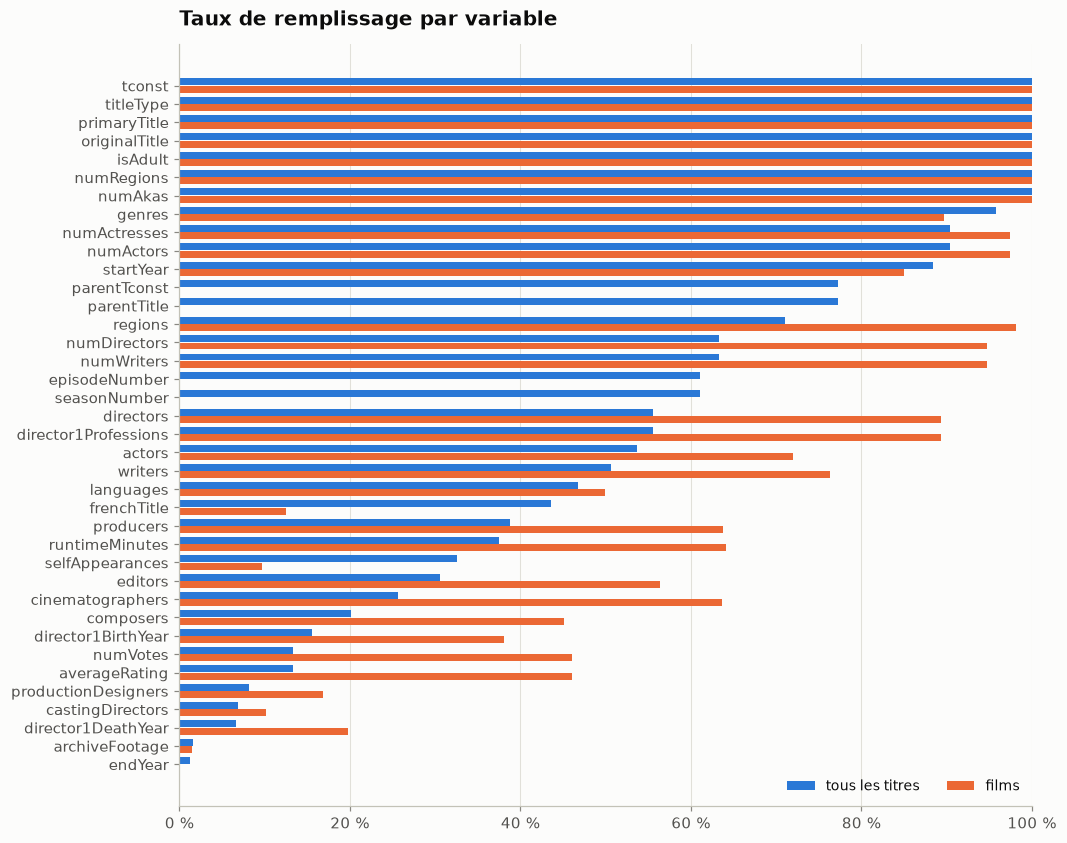

,tous les titres (%),films (%)
tconst,100.0,100.0
titleType,100.0,100.0
primaryTitle,100.0,100.0
originalTitle,100.0,100.0
frenchTitle,43.6,12.5
startYear,88.4,85.0
endYear,1.3,0.0
runtimeMinutes,37.5,64.2
genres,95.8,89.7
isAdult,100.0,100.0


In [5]:
expr = ", ".join(f'100.0 * count("{c}") / count(*) AS "{c}"' for c in colonnes)
remplissage = pd.concat({
    "tous les titres (%)": q(f"SELECT {expr} FROM t").T[0],
    "films (%)": q(f"SELECT {expr} FROM films").T[0],
}, axis=1)
fig, ax = plt.subplots(figsize=(10, 9))
r = remplissage.sort_values("tous les titres (%)")
y = np.arange(len(r))
ax.barh(y + 0.2, r["tous les titres (%)"], height=0.38, color=SERIES[0], label="tous les titres")
ax.barh(y - 0.2, r["films (%)"], height=0.38, color=SERIES[1], label="films")
ax.set_yticks(y, r.index)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(pourcent)
ax.set_xlim(0, 100)
ax.legend(loc="lower right", ncols=2)
ax.set_title("Taux de remplissage par variable")
plt.show()
remplissage.round(1)

**Lecture.** Identifiants, titres, type et `isAdult` sont toujours renseignés. Pour les films, l'essentiel est bien couvert
(genres 90 %, réalisateur 89 %, année 85 %, au moins un acteur 72 %), mais **seuls 46 % des films ont une note**,
64 % une durée et 12,5 % un titre français. Les colonnes `parentTconst`, `seasonNumber`… ne concernent que les épisodes,
et `endYear` que les séries : leur faible remplissage est normal.

### Statistiques descriptives des variables numériques (films)

In [6]:
num = ["startYear", "runtimeMinutes", "averageRating", "numVotes", "numDirectors", "numWriters",
       "numActors", "numActresses", "numAkas", "numRegions", "director1BirthYear"]
desc = q(f"SUMMARIZE SELECT {', '.join(num)} FROM films")
desc = desc.set_index("column_name")[["count", "null_percentage", "min", "q25", "q50", "q75", "max", "avg", "std"]]
desc = desc.apply(pd.to_numeric, errors='coerce').round(2)
desc.columns = ["n", "% vides", "min", "Q1", "médiane", "Q3", "max", "moyenne", "écart-type"]
desc

,n,% vides,min,Q1,médiane,Q3,max,moyenne,écart-type
column_name,,,,,,,,,
startYear,756726,15.00,1894.0,1978.00,2008.00,2018.00,2032.0,1995.28,30.06
runtimeMinutes,756726,35.84,1.0,73.00,89.00,100.00,51420.0,89.89,113.52
averageRating,756726,53.95,1.0,5.31,6.26,7.09,10.0,6.15,1.38
numVotes,756726,53.95,5.0,21.00,65.00,330.00,3237527.0,3721.01,38177.52
numDirectors,756726,5.23,0.0,1.00,1.00,1.00,88.0,1.06,0.71
numWriters,756726,5.23,0.0,1.00,1.00,2.00,69.0,1.36,1.21
numActors,756726,2.57,0.0,0.00,6.00,10.00,46.0,5.62,4.43
numActresses,756726,2.57,0.0,0.00,2.00,3.00,35.0,2.02,2.03
numAkas,756726,0.02,1.0,2.00,3.00,9.00,251.0,6.59,7.77


**Lecture.** Quelques valeurs extrêmes à garder en tête : une durée maximale de 51 420 minutes (film expérimental),
des années de sortie jusqu'à 2032 (films annoncés). `numVotes` est extrêmement asymétrique : médiane de 65 votes
contre une moyenne de 3 721. On raisonne donc en **médianes** et en **échelle logarithmique** pour cette variable.

## 2. Types de titres et production dans le temps

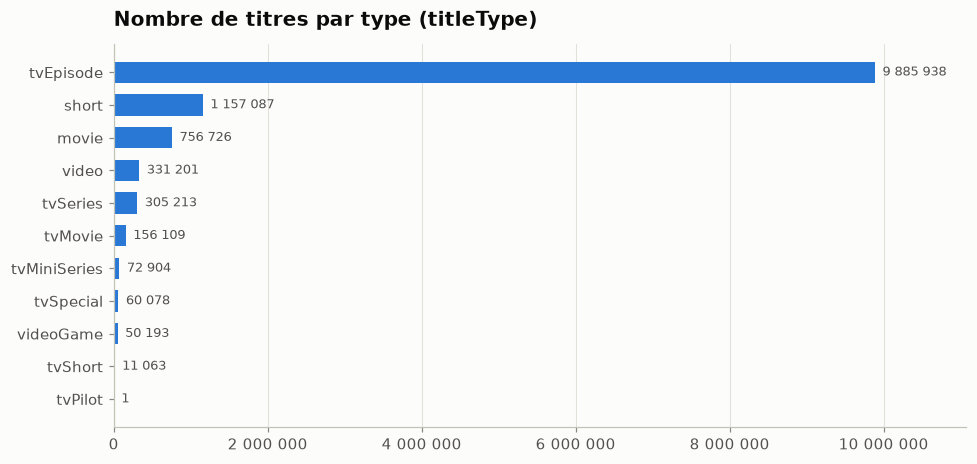

,n,part (%)
titleType,,
tvEpisode,9 885 938,77.3
short,1 157 087,9.0
movie,756 726,5.9
video,331 201,2.6
tvSeries,305 213,2.4
tvMovie,156 109,1.2
tvMiniSeries,72 904,0.6
tvSpecial,60 078,0.5
videoGame,50 193,0.4


In [7]:
types = q("SELECT titleType, count(*) AS n FROM t GROUP BY 1")
types["part (%)"] = 100 * types["n"] / types["n"].sum()
barh(types, "titleType", "n", "Nombre de titres par type (titleType)")
plt.show()
types.sort_values("n", ascending=False).pipe(tableau, {"n": "{:,.0f}", "part (%)": "{:.1f}"})

**Lecture.** La base est dominée par les **épisodes de séries (77 % des lignes)**. Les films ne représentent que 5,9 %
des titres (756 726), derrière les courts-métrages (9 %).

### Nouveaux titres par année, par type
Petits multiples : chaque type a sa propre échelle verticale (les épisodes écraseraient tout le reste sur un axe commun).

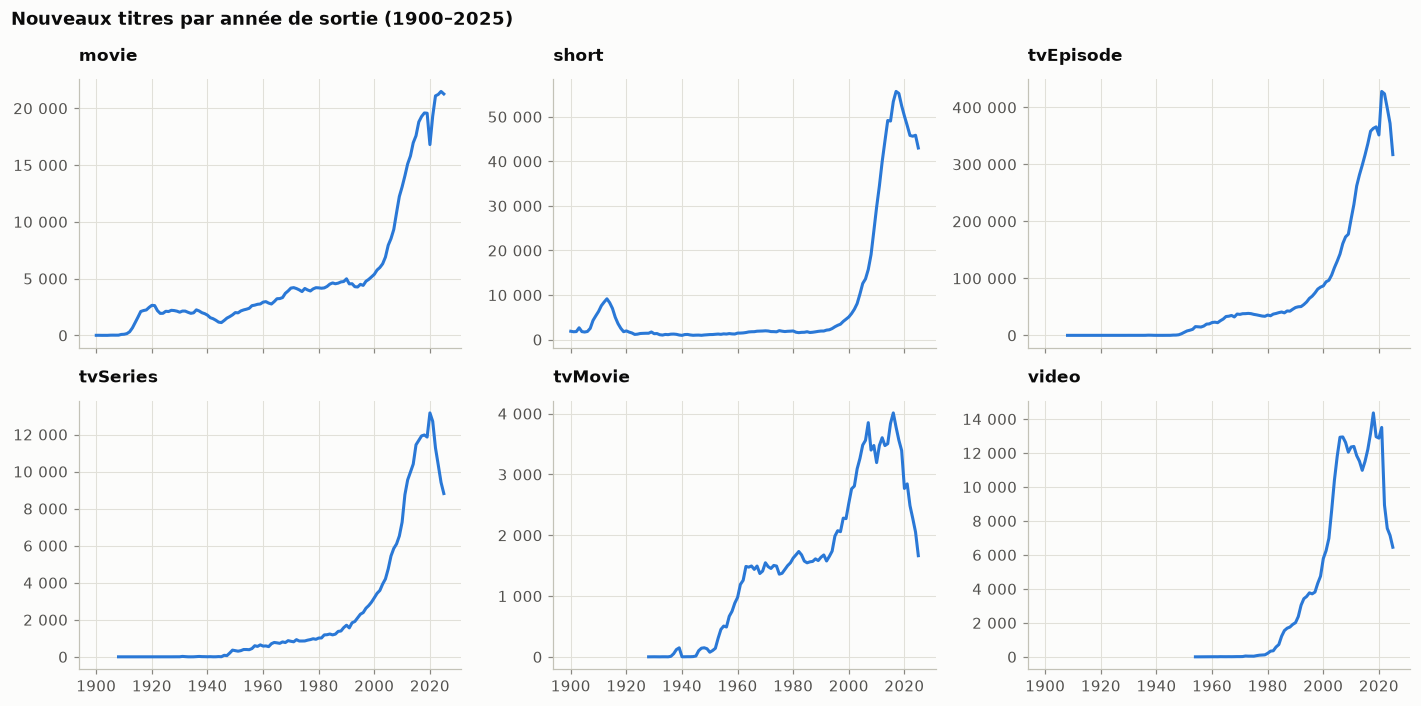

In [8]:
TYPES_PRINC = ["movie", "short", "tvEpisode", "tvSeries", "tvMovie", "video"]
par_an = q(f'''
    SELECT titleType, startYear, count(*) AS n FROM t
    WHERE startYear BETWEEN 1900 AND {ANNEE_MAX} AND titleType IN {tuple(TYPES_PRINC)}
    GROUP BY 1, 2 ORDER BY 2
''')
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, ty in zip(axes.flat, TYPES_PRINC):
    d = par_an[par_an.titleType == ty]
    ax.plot(d.startYear, d.n, color=BLEU)
    ax.set_title(ty, fontsize=11)
    ax.yaxis.set_major_formatter(milliers)
fig.suptitle(f"Nouveaux titres par année de sortie (1900–{ANNEE_MAX})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

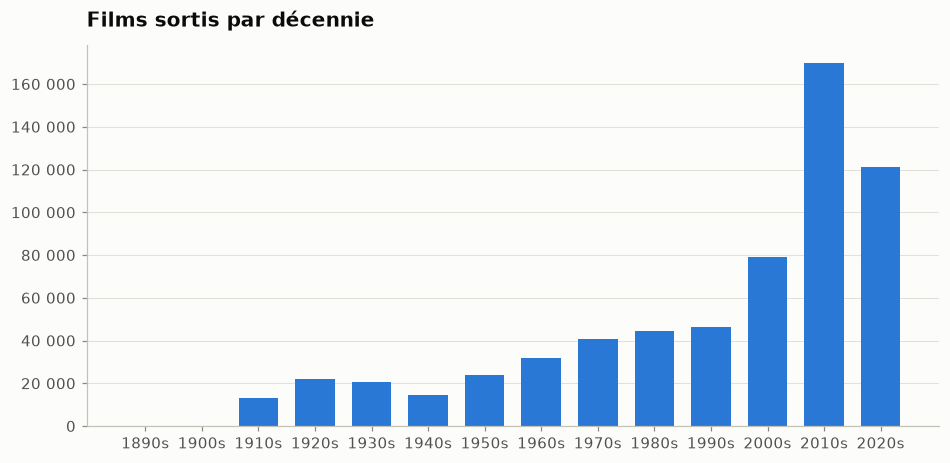

In [9]:
# Films : production par décennie
dec = q(f'''
    SELECT (startYear // 10) * 10 AS decennie, count(*) AS films
    FROM films WHERE startYear BETWEEN 1890 AND {ANNEE_MAX}
    GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.bar(dec.decennie.astype(str) + "s", dec.films, width=0.7, color=BLEU)
ax.yaxis.set_major_formatter(milliers)
ax.grid(axis="x", visible=False)
ax.set_title("Films sortis par décennie")
plt.show()

**Lecture.** La production référencée explose après 2000 pour tous les types : la production réelle a augmenté
(numérique, plateformes), et IMDb couvre beaucoup mieux les titres récents. Pour les films, on voit un **creux net en 2020**
(COVID) suivi d'un rebond. La baisse des toutes dernières années pour les séries, vidéos et téléfilms vient en partie du délai
de référencement dans IMDb. Les courts-métrages ont un premier pic dans les années 1910, l'époque où le cinéma était surtout fait de films courts.

## 3. Durée (`runtimeMinutes`)

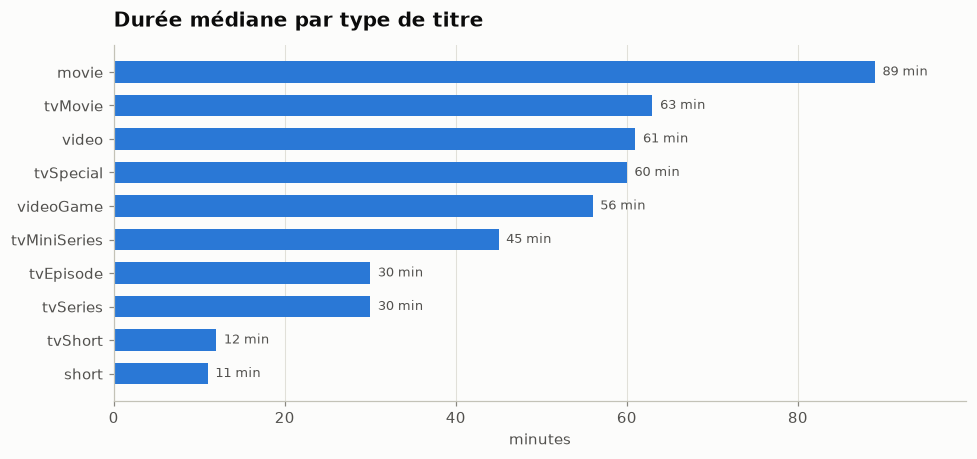

In [10]:
duree_type = q('''
    SELECT titleType, quantile_cont(runtimeMinutes, 0.5) AS mediane, count(runtimeMinutes) AS n
    FROM t WHERE runtimeMinutes BETWEEN 1 AND 1000
    GROUP BY 1
''')
barh(duree_type, "titleType", "mediane", "Durée médiane par type de titre", fmt="{:.0f} min", xlabel="minutes")
plt.show()

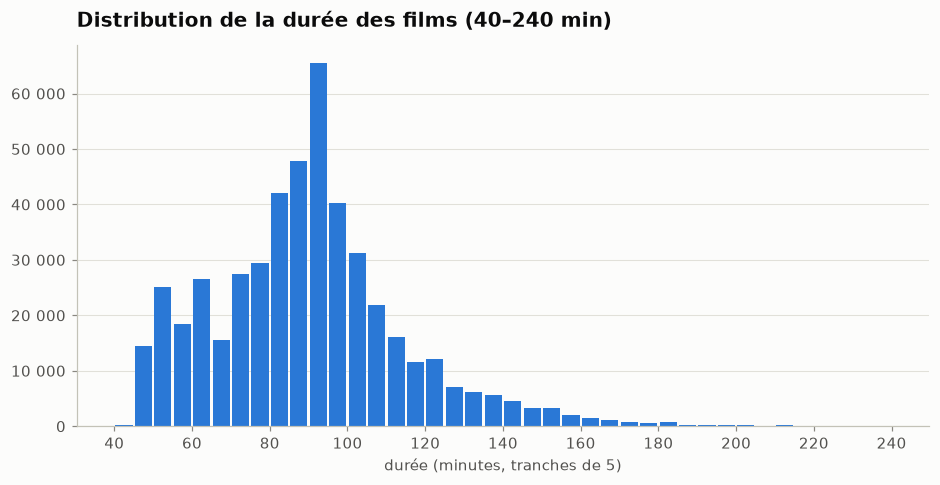

,pct_80_120_min
0,58.159972


In [11]:
hist = q('''
    SELECT (runtimeMinutes // 5) * 5 AS duree, count(*) AS n
    FROM films WHERE runtimeMinutes BETWEEN 40 AND 239
    GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.bar(hist.duree + 2.5, hist.n, width=4.4, color=BLEU)
ax.yaxis.set_major_formatter(milliers)
ax.grid(axis="x", visible=False)
ax.set_xticks(range(40, 241, 20))
ax.set_xlabel("durée (minutes, tranches de 5)")
ax.set_title("Distribution de la durée des films (40–240 min)")
plt.show()
q("SELECT count(*) FILTER (WHERE runtimeMinutes BETWEEN 80 AND 120) * 100.0 / count(runtimeMinutes) AS pct_80_120_min FROM films")

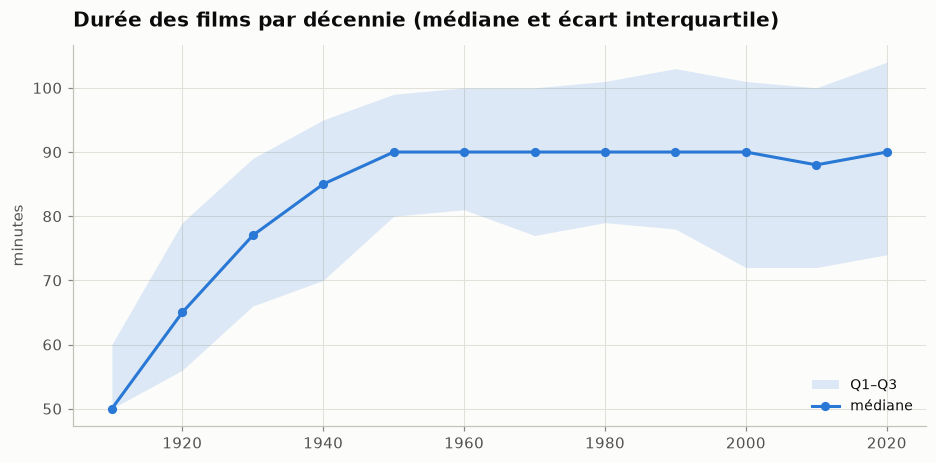

decennie,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
q1,50.0,56.0,66.0,70.0,80.0,81.0,77.0,79.0,78.0,72.0,72.0,74.0
mediane,50.0,65.0,77.0,85.0,90.0,90.0,90.0,90.0,90.0,90.0,88.0,90.0
q3,60.0,79.0,89.0,95.0,99.0,100.0,100.0,101.0,103.0,101.0,100.0,104.0


In [12]:
duree_dec = q(f'''
    SELECT (startYear // 10) * 10 AS decennie,
           quantile_cont(runtimeMinutes, 0.25) AS q1,
           quantile_cont(runtimeMinutes, 0.5) AS mediane,
           quantile_cont(runtimeMinutes, 0.75) AS q3
    FROM films WHERE startYear BETWEEN 1910 AND {ANNEE_MAX} AND runtimeMinutes BETWEEN 40 AND 400
    GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.fill_between(duree_dec.decennie, duree_dec.q1, duree_dec.q3, color=BLEU, alpha=0.15, linewidth=0, label="Q1–Q3")
ax.plot(duree_dec.decennie, duree_dec.mediane, color=BLEU, marker="o", markersize=5, label="médiane")
ax.set_ylabel("minutes")
ax.set_title("Durée des films par décennie (médiane et écart interquartile)")
ax.legend(loc="lower right")
plt.show()
duree_dec.set_index("decennie").T

**Lecture.** Le film est le format le plus long (89 min en médiane), loin devant le téléfilm (63 min) ; un épisode dure
30 min et un court-métrage 11 min en médiane. **58 % des films durent entre 80 et 120 minutes**, avec un pic très marqué
sur la tranche 90–94 min. Il existe aussi une bosse vers 50–65 min (films anciens, documentaires, moyens-métrages).
La durée médiane des films a fortement augmenté jusqu'aux années 1950 (de 50 à 90 min), puis s'est **stabilisée autour de 90 min**
depuis 70 ans. Seul le 3ᵉ quartile remonte légèrement dans les années 2020 (104 min).

## 4. Genres (`genres`)
Un titre peut avoir jusqu'à 3 genres ; on éclate la colonne pour compter chaque genre.

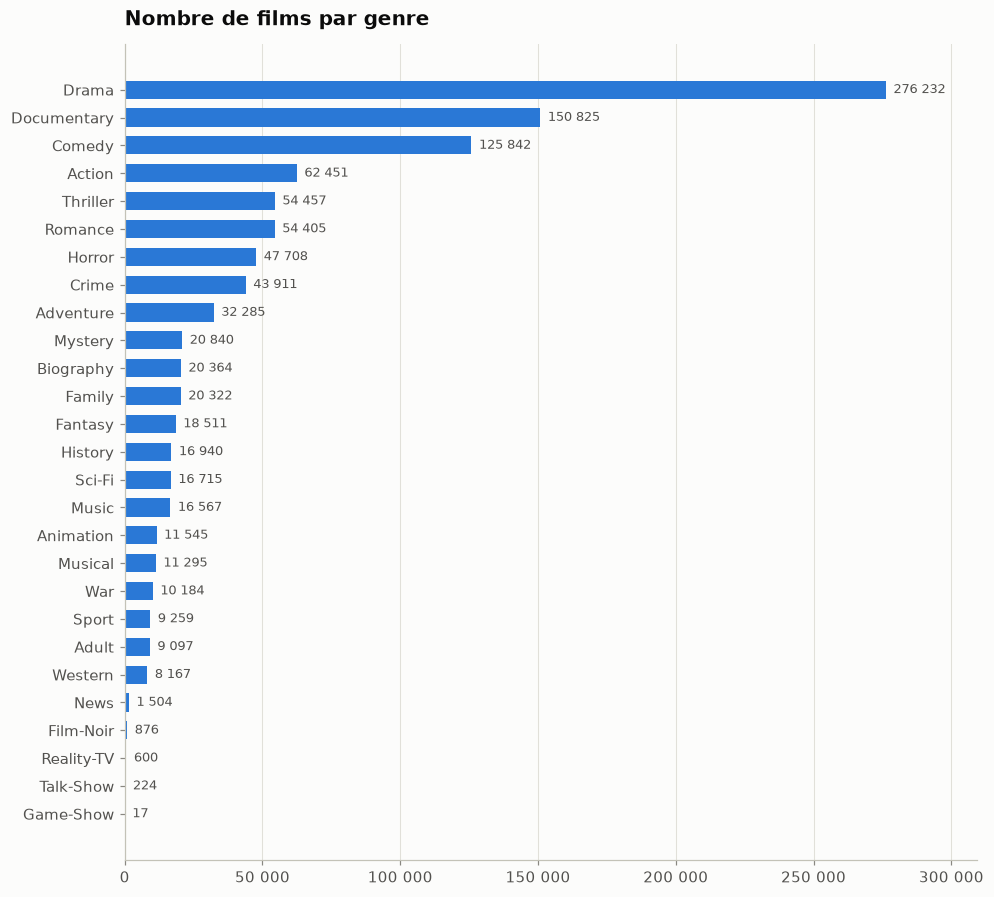

In [13]:
con.execute('''
    CREATE OR REPLACE VIEW films_genres AS
    SELECT tconst, startYear, averageRating, numVotes, unnest(string_split(genres, ',')) AS genre
    FROM films WHERE genres IS NOT NULL
''')
genres = q('''SELECT genre, count(*) AS films FROM films_genres GROUP BY 1''')
barh(genres, "genre", "films", "Nombre de films par genre")
plt.show()

,films,part (%)
nb_genres,,
1,426 595,62.9
2,141 863,20.9
3,110 274,16.2


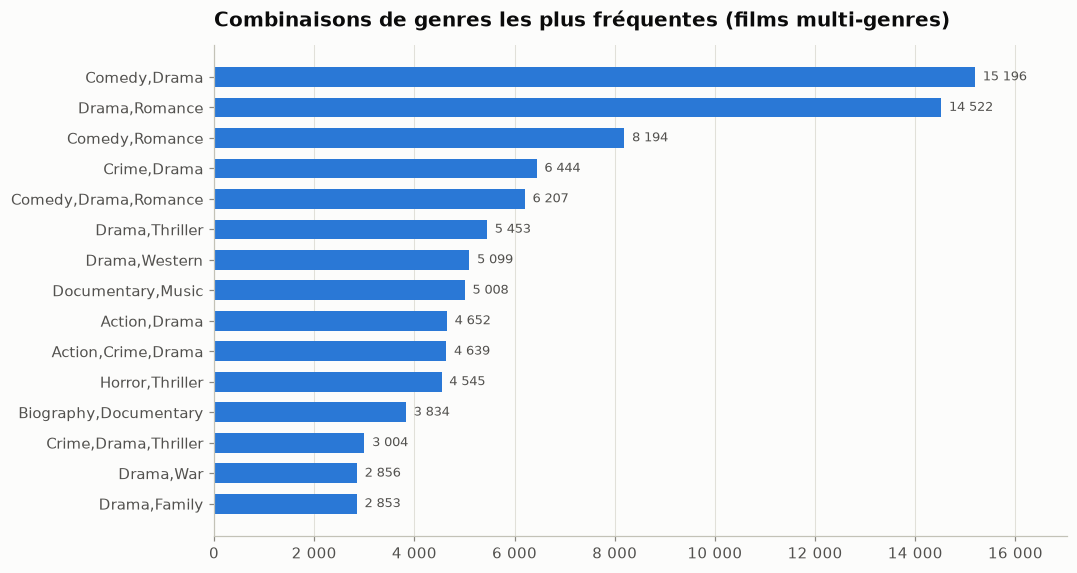

In [14]:
nb_genres = q('''
    SELECT len(string_split(genres, ',')) AS nb_genres, count(*) AS films
    FROM films WHERE genres IS NOT NULL GROUP BY 1 ORDER BY 1
''')
nb_genres["part (%)"] = 100 * nb_genres.films / nb_genres.films.sum()
combos = q('''SELECT genres AS combinaison, count(*) AS films FROM films
              WHERE genres LIKE '%,%' GROUP BY 1 ORDER BY 2 DESC LIMIT 15''')
display(nb_genres.pipe(tableau, {"films": "{:,.0f}", "part (%)": "{:.1f}"}))
barh(combos, "combinaison", "films", "Combinaisons de genres les plus fréquentes (films multi-genres)")
plt.show()

### Évolution des genres par décennie
Part des films de chaque décennie étiquetés avec le genre (un film multi-genres compte dans chacun, donc les colonnes ne somment pas à 100 %).

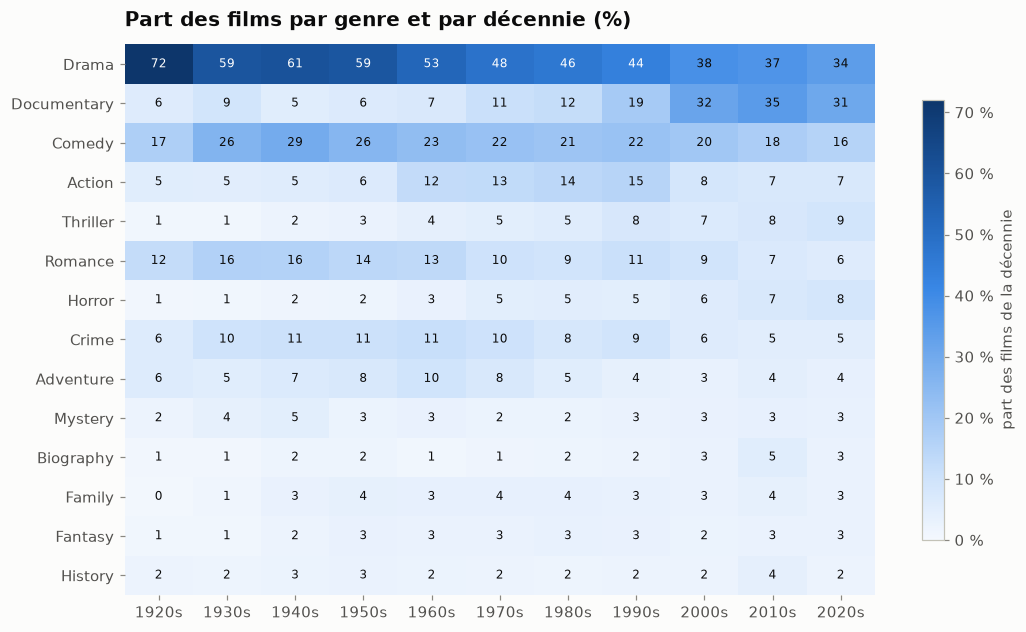

In [15]:
TOP_GENRES = genres.sort_values("films", ascending=False).genre.head(14).tolist()
part_genre = q(f'''
    WITH g AS (SELECT (startYear // 10) * 10 AS decennie, genre, tconst FROM films_genres
               WHERE startYear BETWEEN 1920 AND {ANNEE_MAX}),
    tot AS (SELECT (startYear // 10) * 10 AS decennie, count(*) AS n FROM films
            WHERE startYear BETWEEN 1920 AND {ANNEE_MAX} AND genres IS NOT NULL GROUP BY 1)
    SELECT g.decennie, genre, 100.0 * count(*) / any_value(tot.n) AS part
    FROM g JOIN tot USING (decennie) GROUP BY 1, 2
''').pivot(index="genre", columns="decennie", values="part").loc[TOP_GENRES]

fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(part_genre.values, cmap=SEQ, aspect="auto", vmin=0)
ax.set_xticks(range(part_genre.shape[1]), [f"{d}s" for d in part_genre.columns])
ax.set_yticks(range(part_genre.shape[0]), part_genre.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
seuil = np.nanmax(part_genre.values) * 0.55
for i in range(part_genre.shape[0]):
    for j in range(part_genre.shape[1]):
        v = part_genre.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > seuil else INK)
fig.colorbar(im, ax=ax, format=pourcent, shrink=0.8, label="part des films de la décennie")
ax.set_title("Part des films par genre et par décennie (%)")
plt.show()

**Lecture.** Le **drame** est le genre dominant (276 000 films), devant le documentaire et la comédie.
63 % des films n'ont qu'un genre ; les combinaisons les plus fréquentes sont comédie + drame et drame + romance.
Dans le temps, le drame recule (72 % des films des années 1920, 34 % aujourd'hui), au profit du **documentaire**,
passé de 6 % à plus de 30 % des films depuis les années 2000. L'horreur et le thriller progressent régulièrement,
la romance recule (16 % → 6 %). L'action culmine dans les années 1990 (15 %).

## 5. Notes et votes (`averageRating`, `numVotes`)

In [16]:
couverture = q('''
    SELECT titleType, count(*) AS titres, count(averageRating) AS notes,
           100.0 * count(averageRating) / count(*) AS "part notée (%)",
           round(avg(averageRating), 2) AS note_moyenne,
           quantile_cont(numVotes, 0.5) AS votes_median
    FROM t GROUP BY 1 ORDER BY 2 DESC
''')
couverture.pipe(tableau, {"titres": "{:,.0f}", "notes": "{:,.0f}", "part notée (%)": "{:.1f}",
                         "note_moyenne": "{:.2f}", "votes_median": "{:,.0f}"})

,titres,notes,part notée (%),note_moyenne,votes_median
titleType,,,,,
tvEpisode,9 885 938,882 232,8.9,7.42,22
short,1 157 087,184 348,15.9,6.77,16
movie,756 726,348 443,46.0,6.15,64
video,331 201,60 060,18.1,6.63,19
tvSeries,305 213,114 024,37.4,6.78,36
tvMovie,156 109,57 185,36.6,6.57,32
tvMiniSeries,72 904,26 082,35.8,7.09,38
tvSpecial,60 078,14 366,23.9,6.76,29
videoGame,50 193,20 223,40.3,6.64,33


**Lecture.** Seuls 46 % des films et moins de 9 % des épisodes ont une note IMDb (il faut au moins 5 votes).
Les **épisodes sont les mieux notés** (7,4 de moyenne), les films les moins bien notés (6,15).

### Distribution des notes par type
Histogrammes normalisés (part des titres notés de chaque type), tranches de 0,5 point.

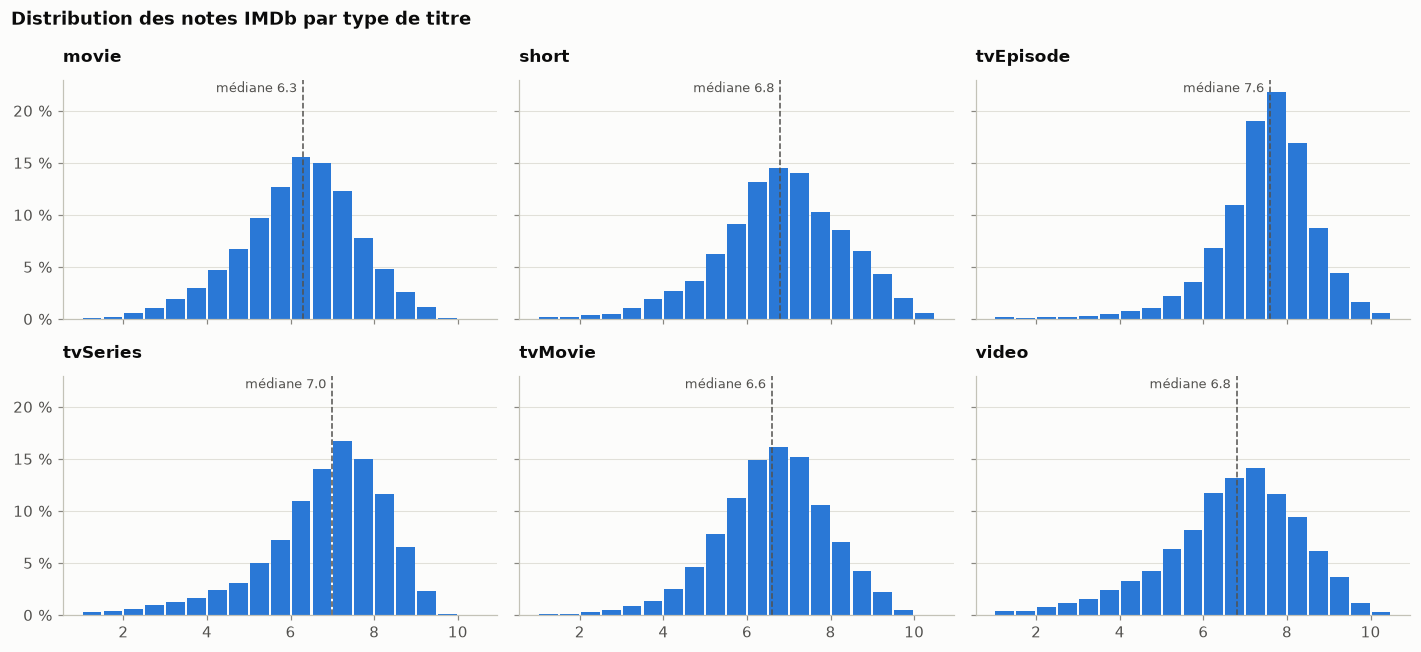

In [17]:
dist = q(f'''
    SELECT titleType, floor(averageRating * 2) / 2 AS note, count(*) AS n
    FROM t WHERE averageRating IS NOT NULL AND titleType IN {tuple(TYPES_PRINC)}
    GROUP BY 1, 2
''')
dist["part"] = 100 * dist.n / dist.groupby("titleType").n.transform("sum")
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, ty in zip(axes.flat, TYPES_PRINC):
    d = dist[dist.titleType == ty]
    ax.bar(d.note + 0.25, d.part, width=0.45, color=BLEU)
    med = con.sql(f"SELECT median(averageRating) FROM t WHERE titleType = '{ty}'").fetchone()[0]
    ax.axvline(med, color=INK2, linewidth=1, linestyle="--")
    ax.text(med - 0.15, 0.95, f"médiane {med:.1f}", transform=ax.get_xaxis_transform(),
            fontsize=8.5, color=INK2, ha="right")
    ax.set_title(ty, fontsize=11)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(pourcent)
fig.suptitle("Distribution des notes IMDb par type de titre", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

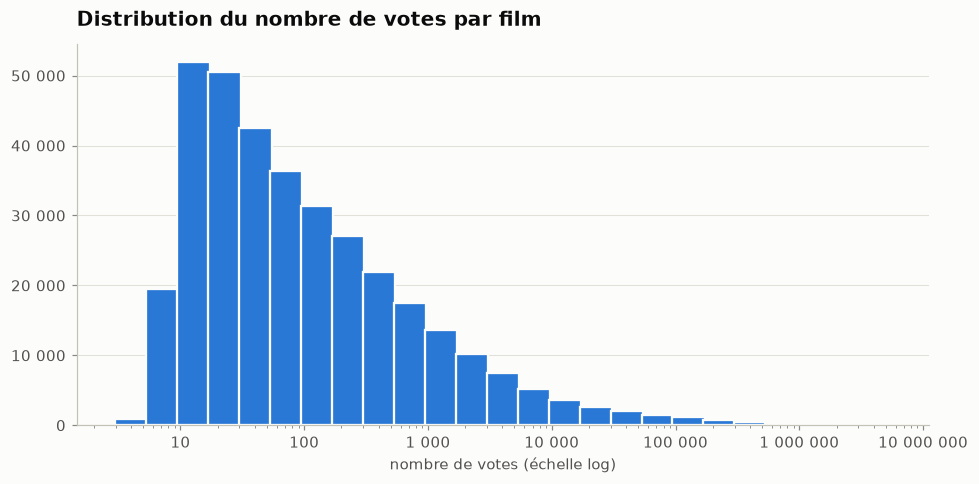

,"médiane, P90, P99",pct films >= 1000 votes
0,"[64.0, 1840.0, 73895.74000000005]",14.086092


In [18]:
votes = q('''
    SELECT floor(log10(numVotes) * 4) / 4 AS lv, count(*) AS n
    FROM films WHERE numVotes > 0 GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.bar(10 ** (votes.lv + 0.125), votes.n, width=10 ** (votes.lv + 0.25) - 10 ** votes.lv, align="center",
       color=BLEU, edgecolor=SURFACE, linewidth=1.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(milliers)
ax.yaxis.set_major_formatter(milliers)
ax.grid(axis="x", visible=False)
ax.set_xlabel("nombre de votes (échelle log)")
ax.set_title("Distribution du nombre de votes par film")
plt.show()
q('''SELECT quantile_cont(numVotes, [0.5, 0.9, 0.99]) AS "médiane, P90, P99",
            100.0 * count(*) FILTER (WHERE numVotes >= 1000) / count(numVotes) AS "pct films >= 1000 votes"
     FROM films''')

### Note et popularité
Les films les plus votés sont-ils mieux notés ? Note médiane par tranche de votes.

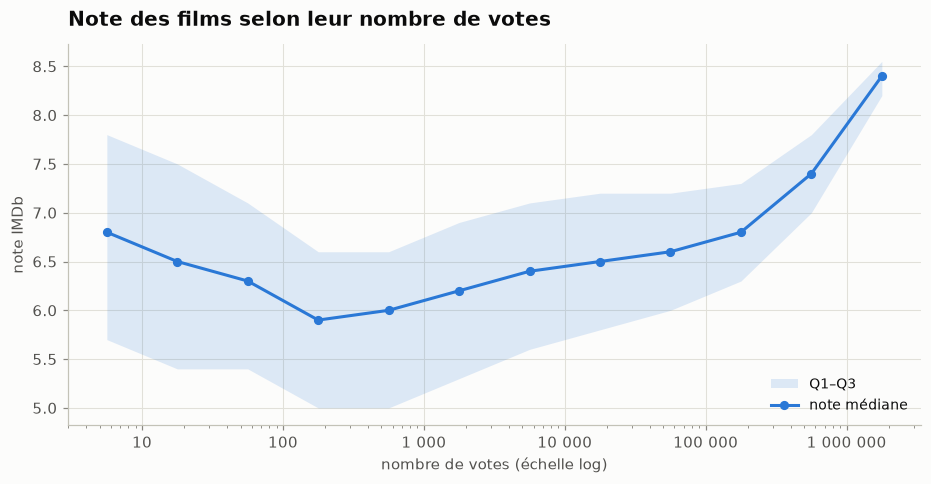

In [19]:
pop = q('''
    SELECT floor(log10(numVotes) * 2) / 2 AS lv, count(*) AS films,
           quantile_cont(averageRating, 0.25) AS q1, median(averageRating) AS mediane,
           quantile_cont(averageRating, 0.75) AS q3
    FROM films WHERE numVotes >= 5 GROUP BY 1 HAVING count(*) >= 30 ORDER BY 1
''')
x = 10 ** (pop.lv + 0.25)
fig, ax = plt.subplots()
ax.fill_between(x, pop.q1, pop.q3, color=BLEU, alpha=0.15, linewidth=0, label="Q1–Q3")
ax.plot(x, pop.mediane, color=BLEU, marker="o", markersize=5, label="note médiane")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(milliers)
ax.set_xlabel("nombre de votes (échelle log)")
ax.set_ylabel("note IMDb")
ax.set_title("Note des films selon leur nombre de votes")
ax.legend(loc="lower right")
plt.show()

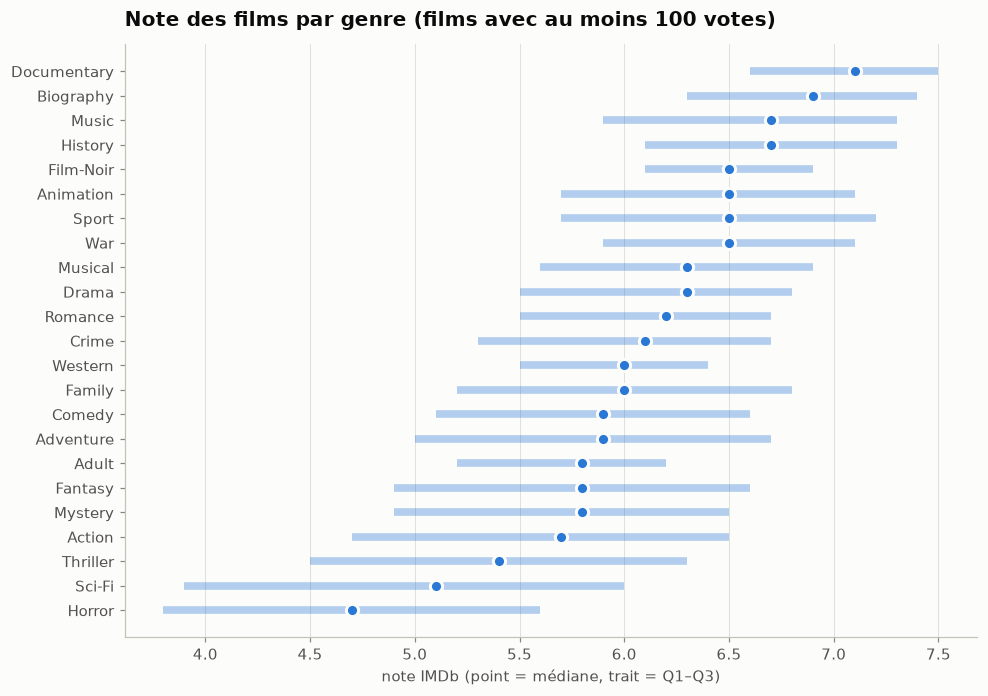

In [20]:
note_genre = q('''
    SELECT genre, count(*) AS films, quantile_cont(averageRating, 0.25) AS q1,
           median(averageRating) AS mediane, quantile_cont(averageRating, 0.75) AS q3
    FROM films_genres WHERE numVotes >= 100 GROUP BY 1 HAVING count(*) >= 200
''').sort_values("mediane")
fig, ax = plt.subplots(figsize=(10, 7))
y = range(len(note_genre))
ax.hlines(y, note_genre.q1, note_genre.q3, color=BLEU, alpha=0.35, linewidth=5)
ax.plot(note_genre.mediane, y, "o", color=BLEU, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_yticks(list(y), note_genre.genre)
ax.grid(axis="y", visible=False)
ax.set_xlabel("note IMDb (point = médiane, trait = Q1–Q3)")
ax.set_title("Note des films par genre (films avec au moins 100 votes)")
plt.show()

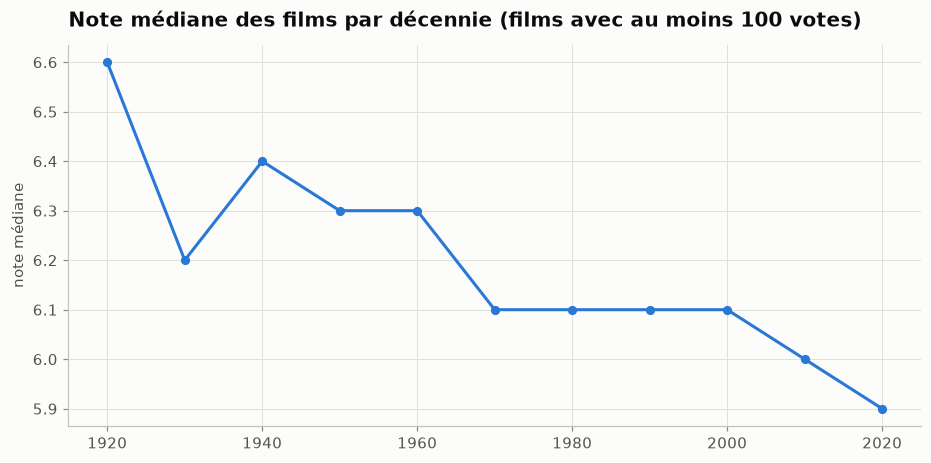

In [21]:
note_dec = q(f'''
    SELECT (startYear // 10) * 10 AS decennie, count(*) AS films, median(averageRating) AS mediane,
           avg(averageRating) AS moyenne
    FROM films WHERE numVotes >= 100 AND startYear BETWEEN 1920 AND {ANNEE_MAX}
    GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.plot(note_dec.decennie, note_dec.mediane, marker="o", markersize=5, color=BLEU)
ax.set_ylabel("note médiane")
ax.set_title("Note médiane des films par décennie (films avec au moins 100 votes)")
plt.show()

**Lecture.**
- **Distribution.** Les notes sont centrées autour de 6–7, avec une queue vers les mauvaises notes. Les épisodes et les séries sont nettement plus haut (médianes 7,6 et 7,0) : seuls les fans votent pour un épisode.
- **Votes.** Un film médian a 64 votes ; 14 % des films dépassent 1 000 votes, et 1 % dépasse ~74 000 votes.
- **Popularité et note.** La relation est en **U** : les films très peu votés ont des notes élevées (votes de l'entourage), la note minimale se situe vers 100–1 000 votes, puis la note remonte nettement avec la popularité (8,4 en médiane au-delà d'un million de votes).
- **Genres.** Le documentaire, la biographie, la musique et l'histoire sont les mieux notés ; **l'horreur (4,7), la science-fiction et le thriller** sont les moins bien notés, avec une forte dispersion.
- **Décennies.** La note médiane baisse régulièrement (6,6 dans les années 1920, 5,9 dans les années 2020). C'est probablement un **biais de survie** : seuls les bons films anciens sont encore vus et notés aujourd'hui.

### Palmarès

In [22]:
print("Top 20 films (au moins 100 000 votes)")
q('''
    SELECT primaryTitle AS titre, startYear AS annee, directors AS realisateurs,
           averageRating AS note, numVotes AS votes
    FROM films WHERE numVotes >= 100000
    ORDER BY averageRating DESC, numVotes DESC LIMIT 20
''').pipe(tableau, {"votes": "{:,.0f}", "note": "{:.1f}"})

Top 20 films (au moins 100 000 votes)


,annee,realisateurs,note,votes
titre,,,,
The Shawshank Redemption,1994,Frank Darabont,9.3,3 237 527
The Godfather,1972,Francis Ford Coppola,9.2,2 255 510
The Dark Knight,2008,Christopher Nolan,9.1,3 225 950
The Lord of the Rings: The Return of the King,2003,Peter Jackson,9.0,2 192 540
Schindler's List,1993,Steven Spielberg,9.0,1 602 885
The Godfather Part II,1974,Francis Ford Coppola,9.0,1 512 754
12 Angry Men,1957,Sidney Lumet,9.0,1 002 499
The Lord of the Rings: The Fellowship of the Ring,2001,Peter Jackson,8.9,2 236 289
Inception,2010,Christopher Nolan,8.8,2 867 969


In [23]:
print("Top 15 séries (au moins 50 000 votes)")
q('''
    SELECT primaryTitle AS serie, startYear AS debut, endYear AS fin, averageRating AS note, numVotes AS votes
    FROM t WHERE titleType IN ('tvSeries', 'tvMiniSeries') AND numVotes >= 50000
    ORDER BY averageRating DESC, numVotes DESC LIMIT 15
''').pipe(tableau, {"votes": "{:,.0f}", "note": "{:.1f}", "fin": "{:.0f}"})

Top 15 séries (au moins 50 000 votes)


,debut,fin,note,votes
serie,,,,
Breaking Bad,2008,2013,9.5,2 675 280
Band of Brothers,2001,2001,9.4,604 236
Planet Earth,2006,2006,9.4,236 685
Planet Earth II,2016,2016,9.4,176 766
Chernobyl,2019,2019,9.3,1 064 017
Avatar: The Last Airbender,2005,2008,9.3,455 435
The Wire,2002,2008,9.3,438 968
Blue Planet II,2017,2017,9.3,58 591
Cosmos,1980,1980,9.3,53 703


In [24]:
print("Films les plus votés")
q('''
    SELECT primaryTitle AS titre, startYear AS annee, averageRating AS note, numVotes AS votes
    FROM films ORDER BY numVotes DESC NULLS LAST LIMIT 10
''').pipe(tableau, {"votes": "{:,.0f}", "note": "{:.1f}"})

Films les plus votés


,annee,note,votes
titre,,,
The Shawshank Redemption,1994,9.3,3 237 527
The Dark Knight,2008,9.1,3 225 950
Inception,2010,8.8,2 867 969
Fight Club,1999,8.8,2 660 688
Interstellar,2014,8.7,2 606 025
Forrest Gump,1994,8.8,2 534 246
Pulp Fiction,1994,8.8,2 466 897
The Matrix,1999,8.7,2 277 626
The Godfather,1972,9.2,2 255 510


**Lecture.** Le palmarès est dominé par le cinéma américain des années 1990–2010 (*The Shawshank Redemption* est à la fois
le film le mieux noté et le plus voté, avec 3,2 millions de votes). Quelques titres indiens récents (*12th Fail*, *Punjab '95*)
apparaissent grâce à des campagnes de vote très mobilisées. Côté séries, *Breaking Bad*, *Band of Brothers* et les documentaires
animaliers de la BBC (*Planet Earth*) sont en tête.

## 6. Personnes : réalisateurs, acteurs, compositeurs
Les colonnes de personnes contiennent des noms : deux homonymes sont donc comptés ensemble (cas rare pour les noms les plus fréquents).
Les films adultes (`isAdult = 1`) sont exclus de ces classements.

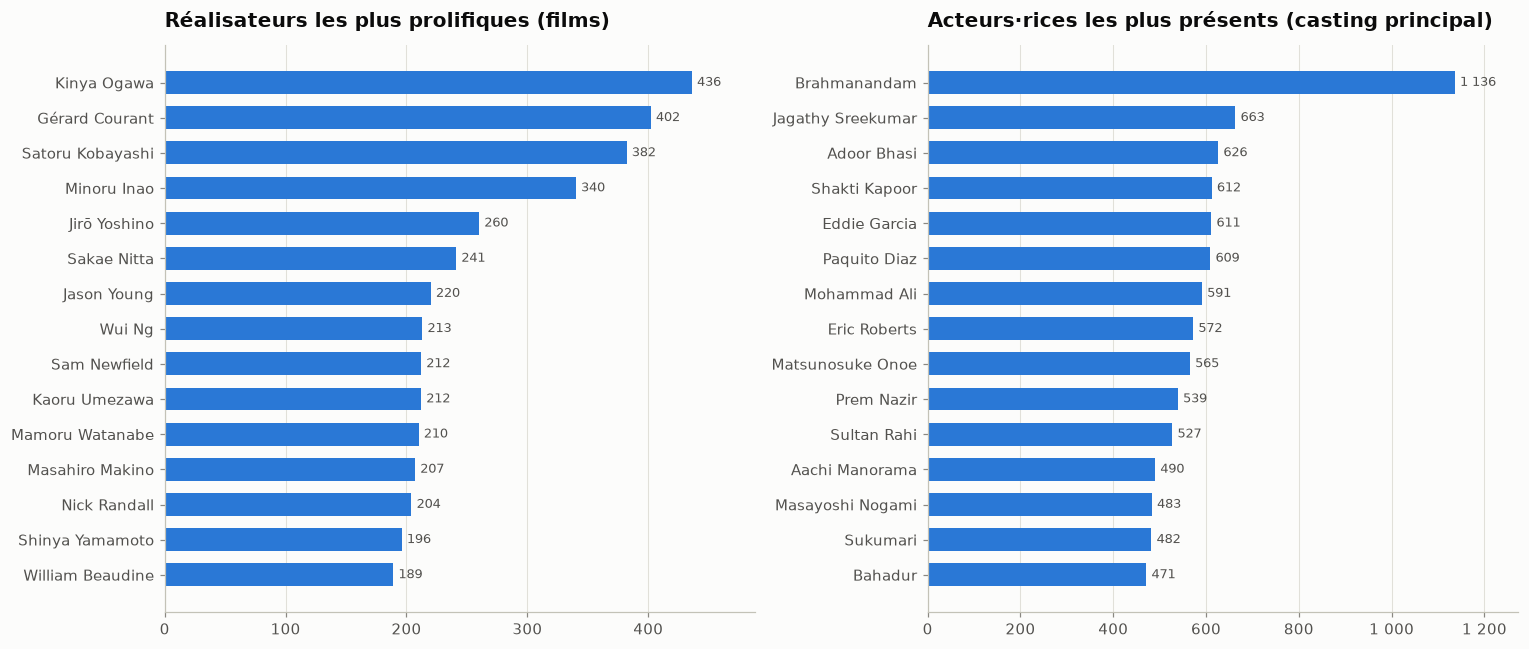

In [25]:
def top_personnes(colonne, n=15, filtre="TRUE"):
    return q(f'''
        SELECT personne, count(*) AS films, round(avg(averageRating), 2) AS note_moyenne
        FROM (SELECT unnest(string_split({colonne}, '{SEP}')) AS personne, averageRating
              FROM films WHERE isAdult = 0 AND {colonne} IS NOT NULL AND {filtre})
        GROUP BY 1 ORDER BY 2 DESC LIMIT {n}
    ''')


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
barh(top_personnes("directors"), "personne", "films", "Réalisateurs les plus prolifiques (films)", ax=axes[0])
barh(top_personnes("actors"), "personne", "films", "Acteurs·rices les plus présents (casting principal)", ax=axes[1])
fig.tight_layout()
plt.show()

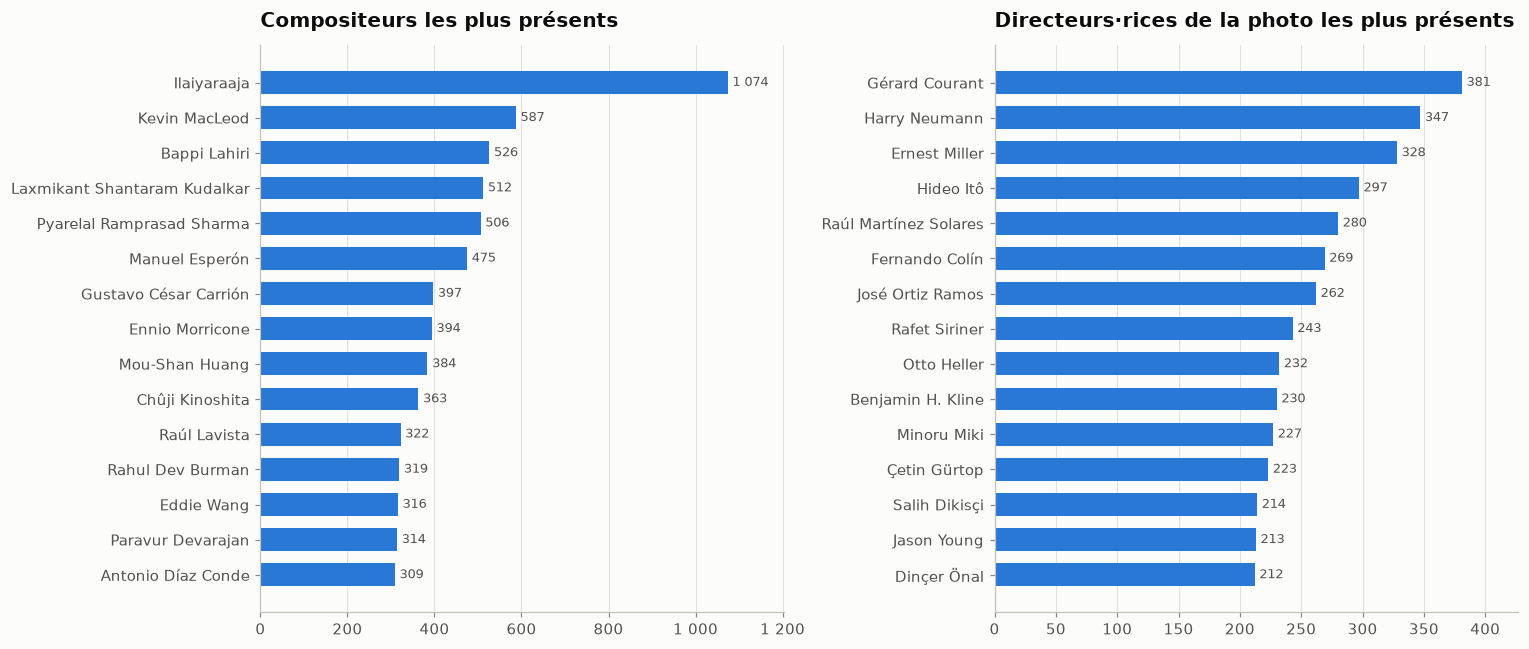

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
barh(top_personnes("composers"), "personne", "films", "Compositeurs les plus présents", ax=axes[0])
barh(top_personnes("cinematographers"), "personne", "films", "Directeurs·rices de la photo les plus présents", ax=axes[1])
fig.tight_layout()
plt.show()

In [27]:
print("Réalisateurs les mieux notés (au moins 5 films ayant chacun au moins 5 000 votes)")
q(f'''
    SELECT personne AS realisateur, count(*) AS films, round(avg(averageRating), 2) AS note_moyenne,
           sum(numVotes) AS votes_total, min(startYear) AS premier, max(startYear) AS dernier
    FROM (SELECT unnest(string_split(directors, '{SEP}')) AS personne, averageRating, numVotes, startYear
          FROM films WHERE numVotes >= 5000)
    GROUP BY 1 HAVING count(*) >= 5 ORDER BY note_moyenne DESC LIMIT 20
''').pipe(tableau, {"votes_total": "{:,.0f}", "note_moyenne": "{:.2f}"})

Réalisateurs les mieux notés (au moins 5 films ayant chacun au moins 5 000 votes)


,films,note_moyenne,votes_total,premier,dernier
realisateur,,,,,
Masaki Kobayashi,6,8.43,163 395,1959,1967
Satyajit Ray,8,8.24,116 908,1955,1969
Leonid Gaidai,5,8.22,79 253,1965,1973
Ertem Eğilmez,15,8.22,248 877,1973,1989
Sergio Leone,6,8.20,2 302 241,1964,1984
Haruo Sotozaki,8,8.19,283 428,2019,2025
Lee Unkrich,5,8.18,4 717 656,1999,2017
Christopher Nolan,13,8.18,19 148 074,1998,2026
Vetrimaaran,6,8.15,117 178,2011,2024


### Place des actrices dans le casting principal
Part des actrices parmi les acteurs·rices crédités dans `title.principals` (films).

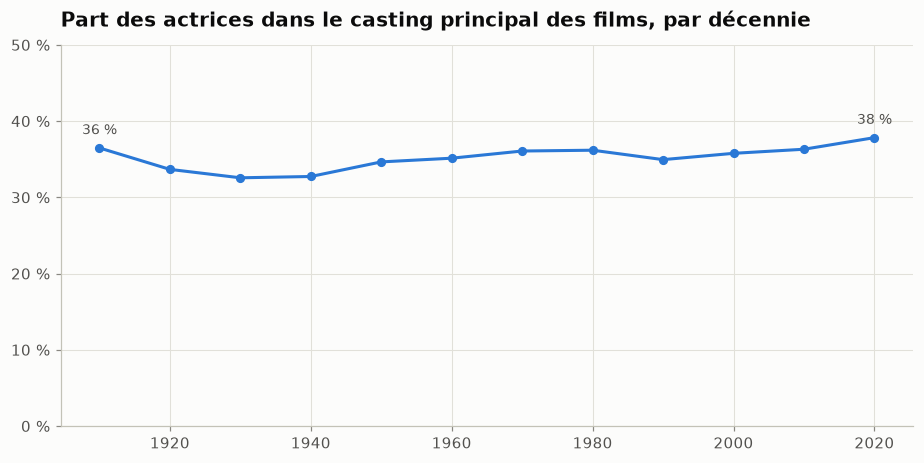

In [28]:
femmes = q(f'''
    SELECT (startYear // 10) * 10 AS decennie,
           100.0 * sum(numActresses) / sum(numActors) AS part_actrices
    FROM films WHERE numActors > 0 AND startYear BETWEEN 1910 AND {ANNEE_MAX}
    GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.plot(femmes.decennie, femmes.part_actrices, marker="o", markersize=5, color=BLEU)
ax.yaxis.set_major_formatter(pourcent)
ax.set_ylim(0, 50)
ax.set_title("Part des actrices dans le casting principal des films, par décennie")
for _, r in femmes.iloc[[0, -1]].iterrows():
    ax.annotate(f"{r.part_actrices:.0f} %", (r.decennie, r.part_actrices), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9, color=INK2)
plt.show()

### Âge du réalisateur à la sortie du film
Calculé avec `startYear - director1BirthYear` (1er réalisateur crédité, année de naissance connue).

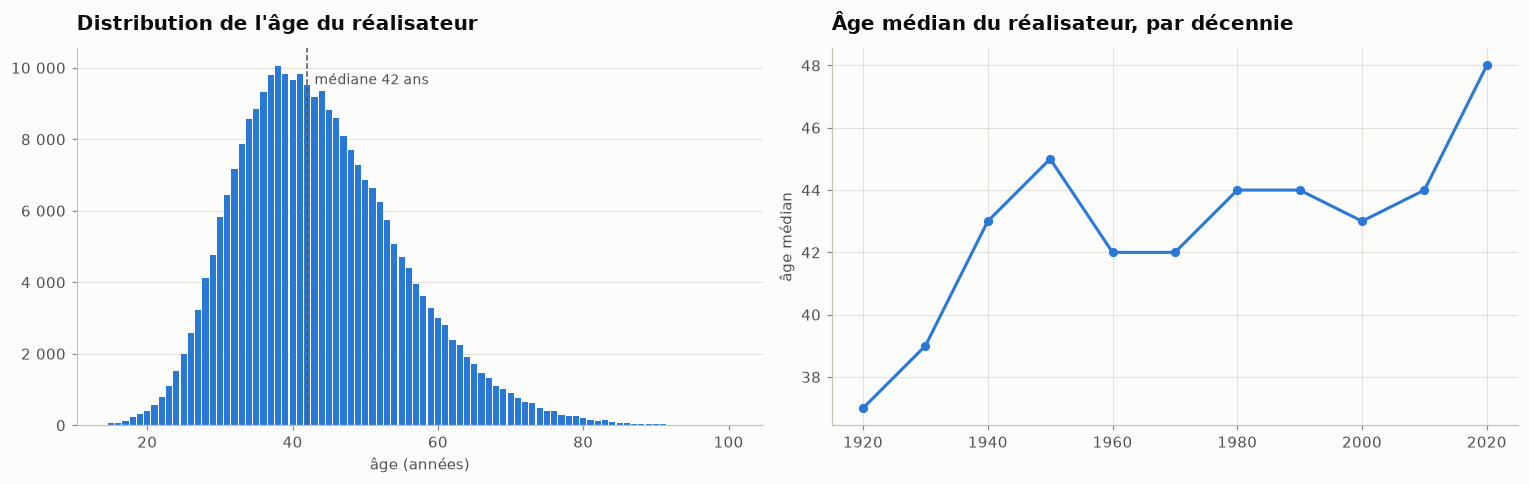

In [29]:
age = q(f'''
    SELECT startYear - director1BirthYear AS age, (startYear // 10) * 10 AS decennie
    FROM films
    WHERE director1BirthYear IS NOT NULL AND startYear <= {ANNEE_MAX}
      AND startYear - director1BirthYear BETWEEN 15 AND 100
''')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h = age.age.value_counts().sort_index()
axes[0].bar(h.index, h.values, width=0.85, color=BLEU)
axes[0].axvline(age.age.median(), color=INK2, linestyle="--", linewidth=1)
axes[0].text(age.age.median() + 1, h.max() * 0.95, f"médiane {age.age.median():.0f} ans", color=INK2, fontsize=9)
axes[0].grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(milliers)
axes[0].set_xlabel("âge (années)")
axes[0].set_title("Distribution de l'âge du réalisateur")
m = age[age.decennie >= 1920].groupby("decennie").age.median()
axes[1].plot(m.index, m.values, marker="o", markersize=5, color=BLEU)
axes[1].set_ylabel("âge médian")
axes[1].set_title("Âge médian du réalisateur, par décennie")
fig.tight_layout()
plt.show()

In [30]:
equipe = q('''
    SELECT CASE WHEN numDirectors >= 3 THEN '3+' ELSE numDirectors::VARCHAR END AS realisateurs,
           count(*) AS films
    FROM films WHERE numDirectors > 0 GROUP BY 1 ORDER BY 1
''')
equipe["part (%)"] = 100 * equipe.films / equipe.films.sum()
equipe.pipe(tableau, {"films": "{:,.0f}", "part (%)": "{:.1f}"})

,films,part (%)
realisateurs,,
1,615 633,91.0
2,51 553,7.6
3+,9 086,1.3


**Lecture.**
- **Réalisateurs prolifiques.** Le classement est dominé par des réalisateurs japonais de films érotiques *pinku eiga* (Kinya Ogawa, Satoru Kobayashi…), rarement marqués `isAdult` dans IMDb, et par le cinéaste expérimental français **Gérard Courant** (402 films, ses *Cinématons*).
- **Acteurs.** Le casting principal est dominé par le cinéma indien (Brahmanandam, 1 136 films) et philippin. « Mohammad Ali » regroupe probablement plusieurs homonymes.
- **Réalisateurs les mieux notés** (≥ 5 films très votés). On trouve les classiques japonais (Kobayashi, Mizoguchi, Ozu, Miyazaki), Satyajit Ray, Sergio Leone, et Christopher Nolan, le seul à combiner régularité et énorme audience (19 millions de votes cumulés).
- **Parité.** Les actrices représentent **environ un tiers du casting principal**, une part quasi stable depuis un siècle (33 % dans les années 1930, 38 % dans les années 2020).
- **Âge.** Un réalisateur a 42 ans en médiane à la sortie de son film ; cet âge médian progresse (37 ans dans les années 1920, 48 ans dans les années 2020).
- **Coréalisation.** 91 % des films ont un seul réalisateur.

## 7. Diffusion internationale (`regions`, `languages`, `frenchTitle`)
`regions` liste les pays où le titre a un titre alternatif dans `title.akas` (un bon indicateur de diffusion).
`XWW` = titre international (« World-wide »).

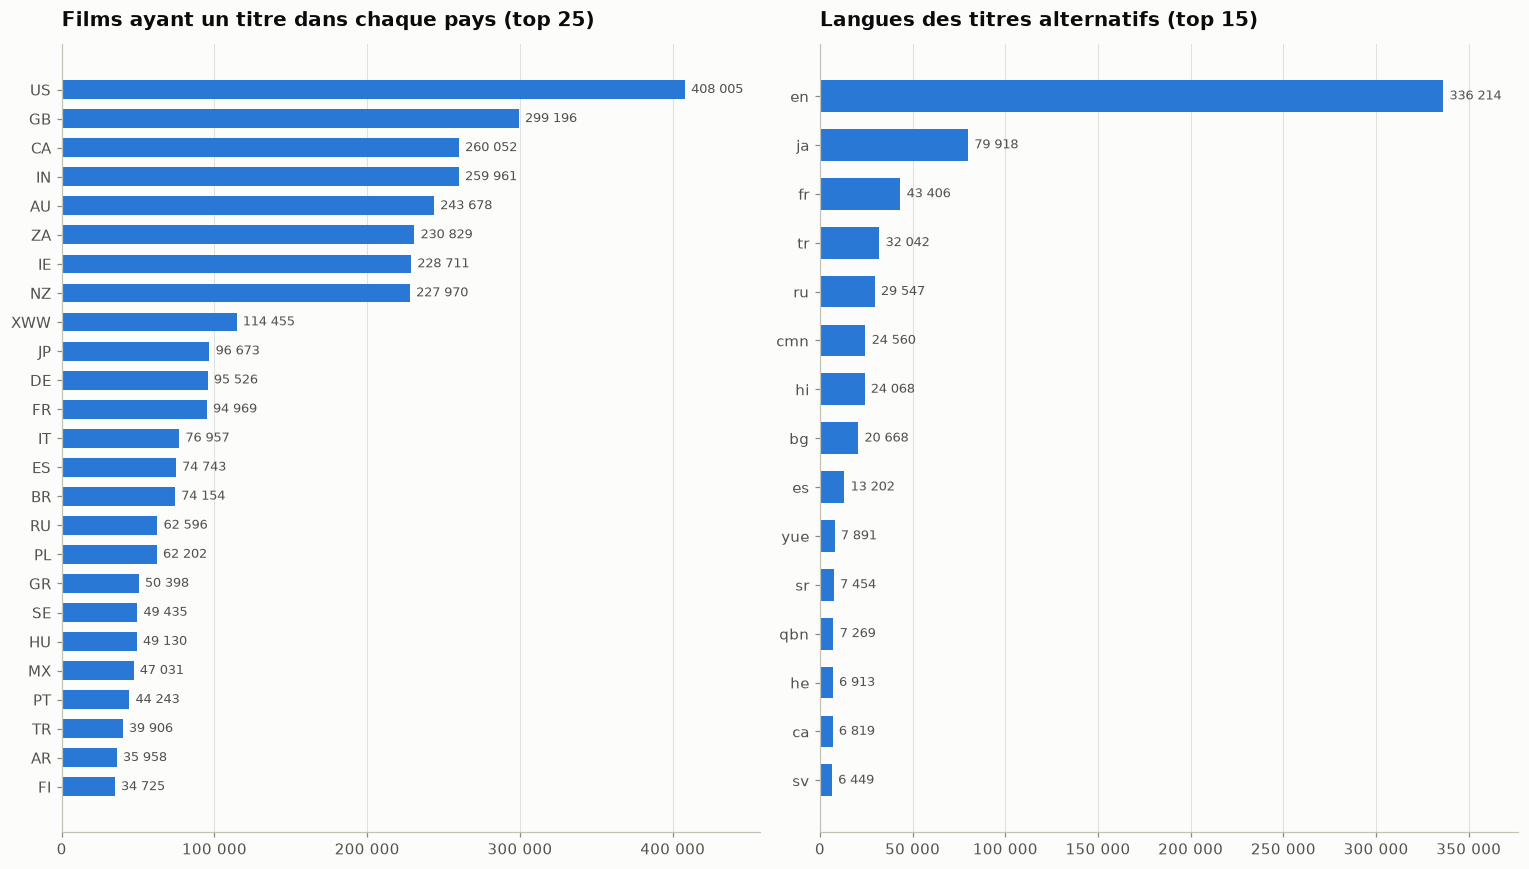

In [31]:
pays = q(f'''
    SELECT region, count(*) AS films
    FROM (SELECT unnest(string_split(regions, '{SEP}')) AS region FROM films WHERE regions IS NOT NULL)
    GROUP BY 1 ORDER BY 2 DESC LIMIT 25
''')
langues = q(f'''
    SELECT langue, count(*) AS films
    FROM (SELECT unnest(string_split(languages, '{SEP}')) AS langue FROM films WHERE languages IS NOT NULL)
    GROUP BY 1 ORDER BY 2 DESC LIMIT 15
''')
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
barh(pays, "region", "films", "Films ayant un titre dans chaque pays (top 25)", ax=axes[0])
barh(langues, "langue", "films", "Langues des titres alternatifs (top 15)", ax=axes[1])
fig.tight_layout()
plt.show()

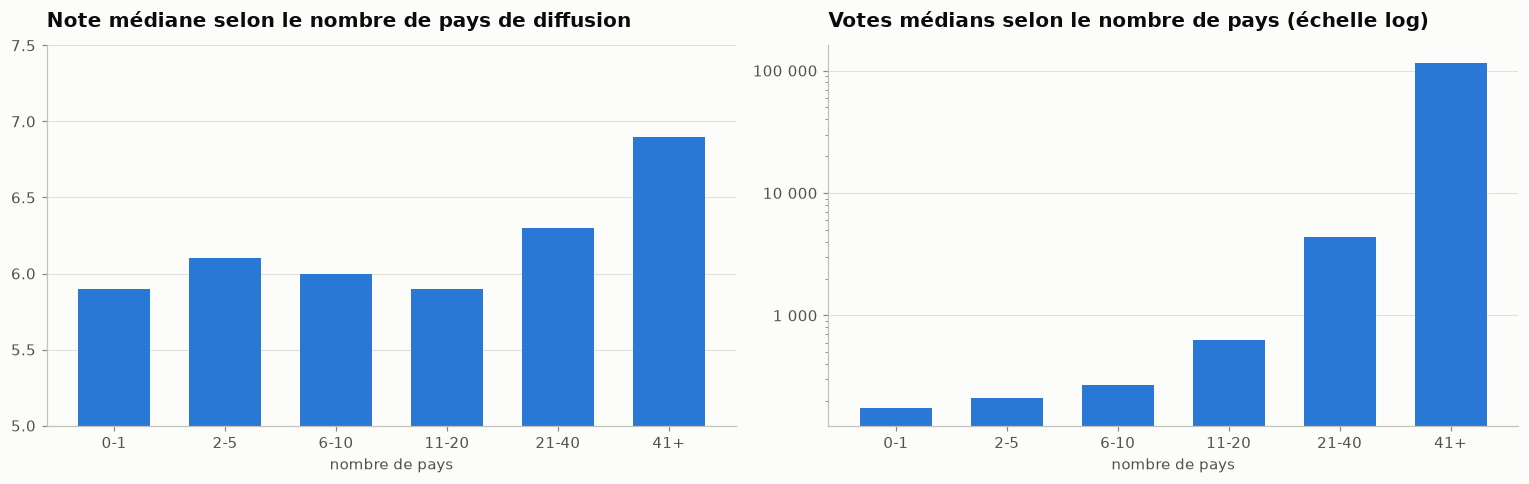

,films,note_mediane,votes_median
pays,,,
0-1,5 079,5.9,174
2-5,22 645,6.1,212
6-10,45 633,6.0,271
11-20,44 951,5.9,631
21-40,24 207,6.3,4 337
41+,4 321,6.9,116 192


In [32]:
diff = q('''
    SELECT CASE WHEN numRegions <= 1 THEN '0-1' WHEN numRegions <= 5 THEN '2-5'
                WHEN numRegions <= 10 THEN '6-10' WHEN numRegions <= 20 THEN '11-20'
                WHEN numRegions <= 40 THEN '21-40' ELSE '41+' END AS pays,
           min(numRegions) AS ordre, count(*) AS films, median(averageRating) AS note_mediane,
           median(numVotes) AS votes_median
    FROM films WHERE numVotes >= 100 GROUP BY 1 ORDER BY ordre
''')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(diff.pays, diff.note_mediane, width=0.65, color=BLEU)
axes[0].set_ylim(5, 7.5)
axes[0].set_title("Note médiane selon le nombre de pays de diffusion")
axes[0].set_xlabel("nombre de pays")
axes[1].bar(diff.pays, diff.votes_median, width=0.65, color=BLEU)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(milliers)
axes[1].set_title("Votes médians selon le nombre de pays (échelle log)")
axes[1].set_xlabel("nombre de pays")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
diff.drop(columns="ordre").pipe(tableau, {"films": "{:,.0f}", "note_mediane": "{:.1f}", "votes_median": "{:,.0f}"})

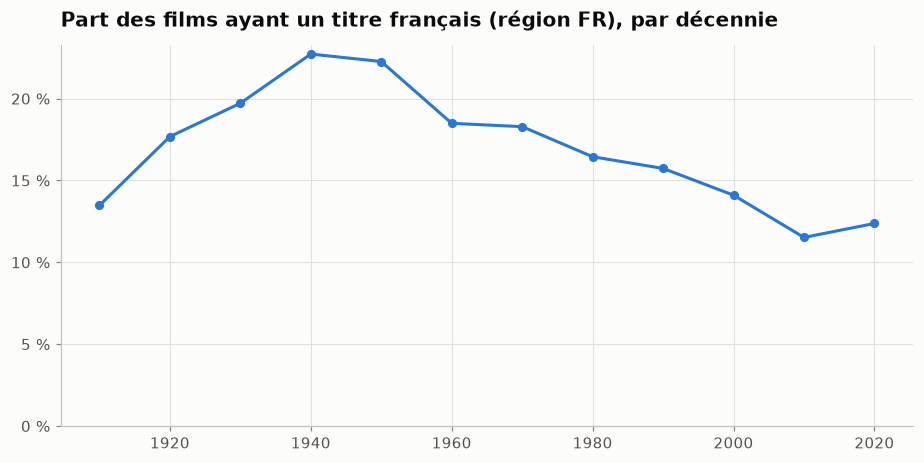

In [33]:
fr = q(f'''
    SELECT (startYear // 10) * 10 AS decennie,
           100.0 * count(frenchTitle) / count(*) AS part_titre_fr
    FROM films WHERE startYear BETWEEN 1910 AND {ANNEE_MAX} GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.plot(fr.decennie, fr.part_titre_fr, marker="o", markersize=5, color=BLEU)
ax.yaxis.set_major_formatter(pourcent)
ax.set_ylim(0)
ax.set_title("Part des films ayant un titre français (région FR), par décennie")
plt.show()

**Lecture.**
- **Pays anglophones surreprésentés.** Les États-Unis, le Royaume-Uni, le Canada, l'Inde, l'Australie, l'Afrique du Sud, l'Irlande et la Nouvelle-Zélande apparaissent pour 230 000 à 400 000 films : IMDb crée souvent automatiquement un titre anglais pour ces régions. Ce n'est donc pas une preuve de sortie en salle. Hors anglophones, le Japon, l'Allemagne et la France arrivent en tête (~95 000 films chacun).
- **Nombre de pays et notoriété.** Le nombre de pays où un film a un titre est très lié à sa notoriété : votes médians de 174 pour 0–1 pays, contre 116 000 au-delà de 40 pays. La note médiane ne progresse vraiment qu'au-delà de 20 pays (6,9 au-delà de 40).
- **Titre français.** La part des films avec un titre français culmine dans les années 1940–1950 (~22 %) et baisse depuis (~12 %). Les titres récents sont plus souvent distribués sous leur titre original, et beaucoup de films ne sortent pas en France.

## 8. Séries et épisodes
Grâce à `parentTconst`, chaque épisode est rattaché à sa série.

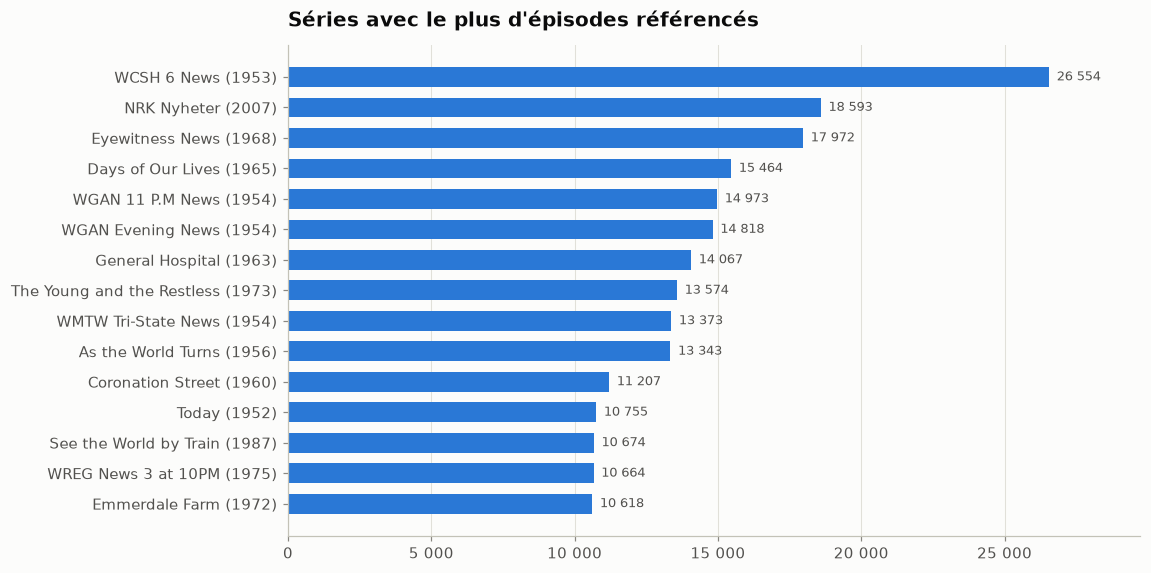

In [34]:
top_series = q('''
    SELECT e.parentTitle || ' (' || coalesce(s.startYear::VARCHAR, '?') || ')' AS serie, count(*) AS episodes
    FROM t e LEFT JOIN t s ON s.tconst = e.parentTconst
    WHERE e.titleType = 'tvEpisode' AND e.parentTconst IS NOT NULL
    GROUP BY e.parentTconst, 1 ORDER BY 2 DESC LIMIT 15
''')
barh(top_series, "serie", "episodes", "Séries avec le plus d'épisodes référencés")
plt.show()

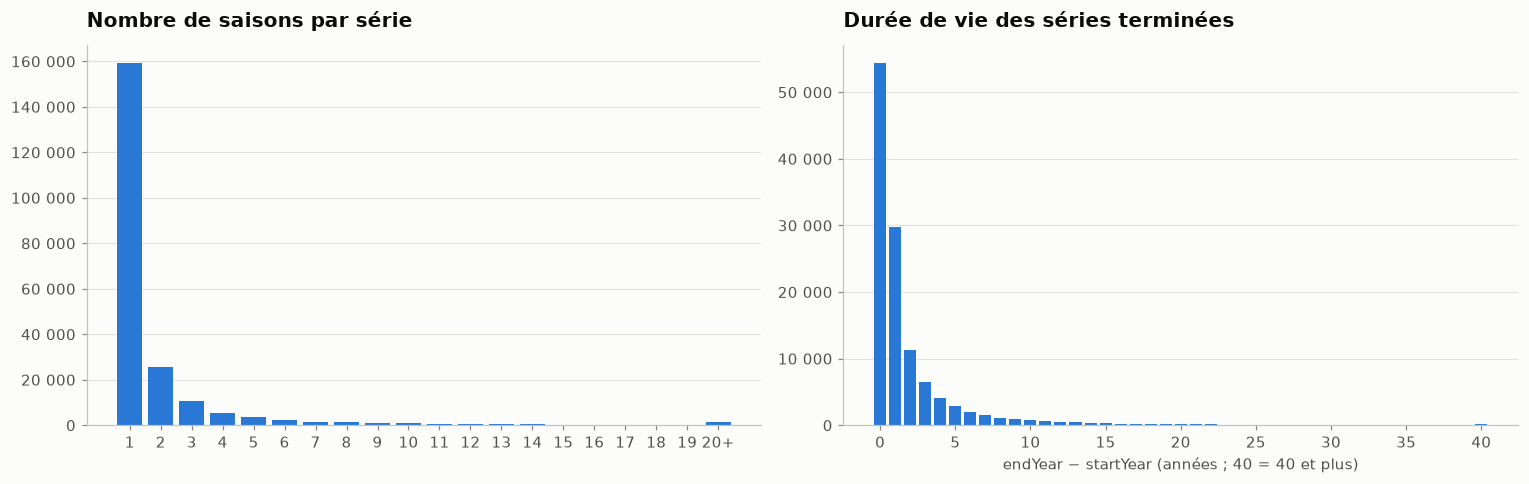

Séries avec une seule saison : 74 %


In [35]:
saisons = q('''
    SELECT LEAST(max(seasonNumber), 20) AS saisons
    FROM t WHERE titleType = 'tvEpisode' AND seasonNumber BETWEEN 1 AND 200
    GROUP BY parentTconst
''').saisons.value_counts().sort_index()
duree_series = q('''
    SELECT LEAST(endYear - startYear, 40) AS ans FROM t
    WHERE titleType = 'tvSeries' AND endYear IS NOT NULL AND endYear >= startYear
''').ans.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(saisons.index, saisons.values, width=0.8, color=BLEU)
axes[0].set_xticks(range(1, 21), [str(i) for i in range(1, 20)] + ["20+"])
axes[0].set_title("Nombre de saisons par série")
axes[1].bar(duree_series.index, duree_series.values, width=0.8, color=BLEU)
axes[1].set_xlabel("endYear − startYear (années ; 40 = 40 et plus)")
axes[1].set_title("Durée de vie des séries terminées")
for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(milliers)
fig.tight_layout()
plt.show()
print(f"Séries avec une seule saison : {100 * saisons.get(1, 0) / saisons.sum():.0f} %")

### Note d'une série vs note moyenne de ses épisodes

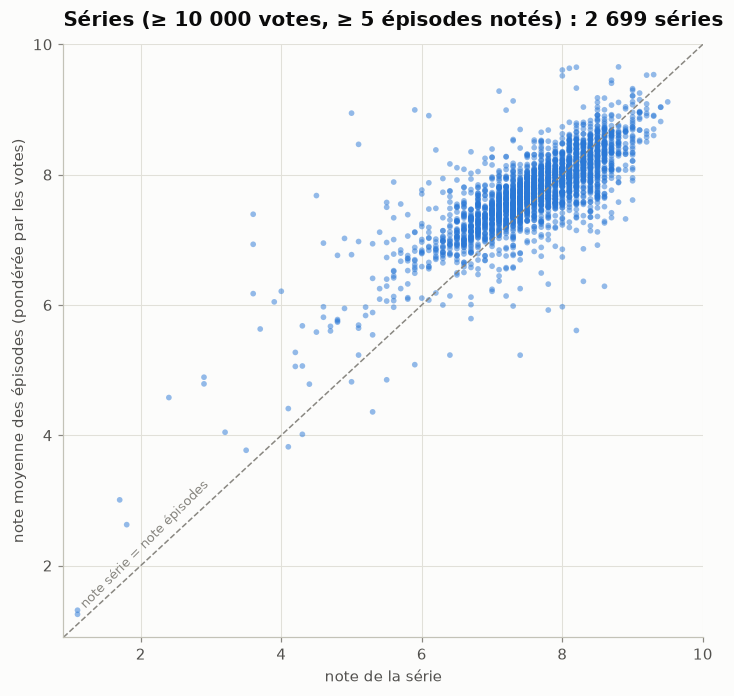

Corrélation : 0.80  —  écart moyen épisodes − série : +0.13 point


In [36]:
se = q('''
    SELECT s.primaryTitle AS serie, s.averageRating AS note_serie, s.numVotes AS votes_serie,
           sum(e.averageRating * e.numVotes) / sum(e.numVotes) AS note_episodes, count(*) AS episodes_notes
    FROM t e JOIN t s ON s.tconst = e.parentTconst
    WHERE e.titleType = 'tvEpisode' AND e.averageRating IS NOT NULL AND s.numVotes >= 10000
    GROUP BY 1, 2, 3 HAVING count(*) >= 5
''')
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(se.note_serie, se.note_episodes, s=14, color=BLEU, alpha=0.5, edgecolor="none")
lim = (min(se.note_serie.min(), se.note_episodes.min()) - 0.2, 10)
ax.plot(lim, lim, color=MUTED, linewidth=1, linestyle="--")
ax.text(lim[0] + 0.2, lim[0] + 0.45, "note série = note épisodes", color=MUTED, fontsize=8.5, rotation=45)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("note de la série")
ax.set_ylabel("note moyenne des épisodes (pondérée par les votes)")
n_se = f"{len(se):,}".replace(",", " ")
ax.set_title(f"Séries (≥ 10 000 votes, ≥ 5 épisodes notés) : {n_se} séries")
plt.show()
print(f"Corrélation : {se.note_serie.corr(se.note_episodes):.2f}  —  "
      f"écart moyen épisodes − série : {(se.note_episodes - se.note_serie).mean():+.2f} point")

**Lecture.** Les séries ayant le plus d'épisodes référencés sont des journaux télévisés locaux américains et des
soap operas (*Days of Our Lives*, *General Hospital*, *Coronation Street*). **74 % des séries n'ont qu'une saison**,
et la plupart des séries terminées s'arrêtent la même année ou l'année suivante. La note d'une série et la note moyenne
de ses épisodes sont **fortement corrélées (0,80)**. Les épisodes sont légèrement mieux notés (+0,13 point), car seuls les fans
votent épisode par épisode. Les séries très mal notées (en bas à gauche) ont des épisodes nettement mieux notés que la série elle-même,
ce qui suggère des votes négatifs ciblés sur la page de la série.

## 9. Corrélations entre variables numériques (films)
Corrélation de **Spearman** (sur les rangs : robuste aux distributions très asymétriques comme `numVotes`).

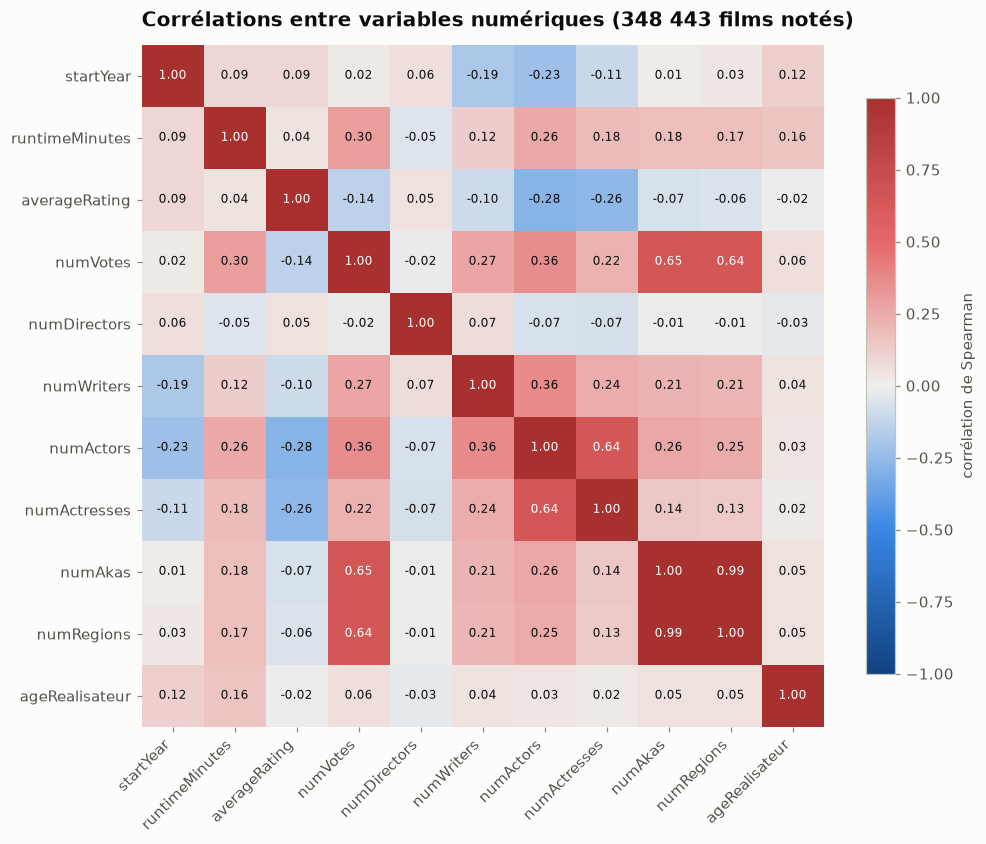

In [37]:
NUM = ["startYear", "runtimeMinutes", "averageRating", "numVotes", "numDirectors", "numWriters",
       "numActors", "numActresses", "numAkas", "numRegions", "ageRealisateur"]
df_num = q(f'''
    SELECT startYear, runtimeMinutes, averageRating, numVotes, numDirectors, numWriters,
           numActors, numActresses, numAkas, numRegions,
           CASE WHEN startYear - director1BirthYear BETWEEN 15 AND 100
                THEN startYear - director1BirthYear END AS ageRealisateur
    FROM films WHERE averageRating IS NOT NULL
''')
corr = df_num[NUM].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=45, ha="right")
ax.set_yticks(range(len(NUM)), NUM)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="corrélation de Spearman")
ax.set_title(f"Corrélations entre variables numériques ({len(df_num):,} films notés)".replace(",", " "))
plt.show()

In [38]:
# Paires les plus corrélées (hors diagonale)
paires = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
paires.reindex(paires.abs().sort_values(ascending=False).index).head(10).to_frame("spearman").round(2)

spearman
numAkas        numRegions        0.99
numVotes       numAkas           0.65
               numRegions        0.64
numActors      numActresses      0.64
numWriters     numActors         0.36
numVotes       numActors         0.36
runtimeMinutes numVotes          0.30
averageRating  numActors        -0.28
numVotes       numWriters        0.27
averageRating  numActresses     -0.26

**Lecture.** `numAkas` et `numRegions` sont quasiment redondantes (0,99) : on peut n'en garder qu'une dans un modèle.
La **popularité** (`numVotes`) est liée à la diffusion internationale (0,65) et, dans une moindre mesure, à la taille
du casting et à la durée. La **note** n'est fortement corrélée à aucune variable numérique : le lien le plus net est
négatif avec le nombre d'acteurs et d'actrices crédités (−0,28), et faible et négatif avec le nombre de votes (−0,14),
à cause de la relation en U vue plus haut. Les films récents créditent moins d'acteurs dans le casting principal (−0,23 avec l'année).

## 10. Contenu adulte (`isAdult`)

In [39]:
q('''
    SELECT titleType, count(*) FILTER (WHERE isAdult = 1) AS titres_adultes,
           100.0 * count(*) FILTER (WHERE isAdult = 1) / count(*) AS "part (%)"
    FROM t GROUP BY 1 ORDER BY 2 DESC
''').pipe(tableau, {"titres_adultes": "{:,.0f}", "part (%)": "{:.2f}"})

,titres_adultes,part (%)
titleType,,
tvEpisode,281 794,2.85
video,115 794,34.96
movie,9 098,1.20
tvSeries,3 141,1.03
short,2 812,0.24
videoGame,2 496,4.97
tvMiniSeries,487,0.67
tvMovie,87,0.06
tvSpecial,36,0.06


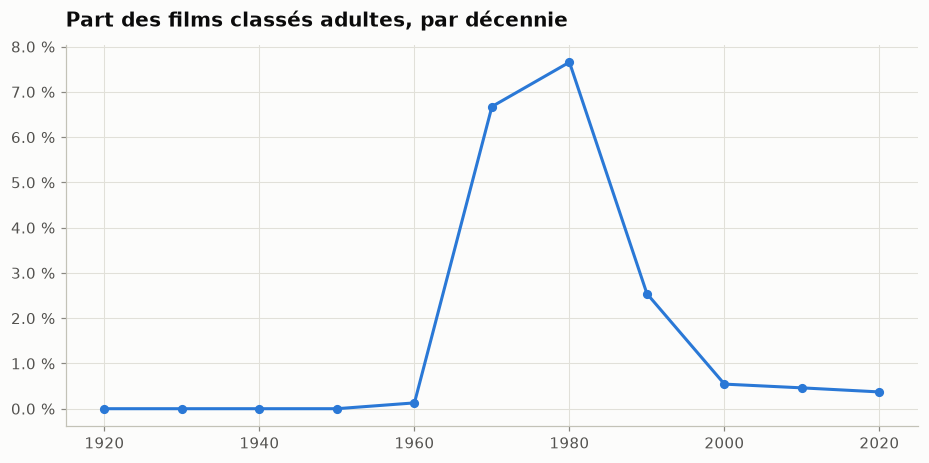

In [40]:
adulte = q(f'''
    SELECT (startYear // 10) * 10 AS decennie, 100.0 * avg(isAdult) AS part_adulte
    FROM films WHERE startYear BETWEEN 1920 AND {ANNEE_MAX} GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots()
ax.plot(adulte.decennie, adulte.part_adulte, marker="o", markersize=5, color=BLEU)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f} %"))
ax.set_title("Part des films classés adultes, par décennie")
plt.show()

**Lecture.** Le contenu adulte se concentre dans les **vidéos (35 % des `video`)**, typique du marché de la vidéo directe.
Il ne concerne que 1,2 % des films, et le marquage est incomplet : beaucoup de films érotiques japonais, par exemple, ne sont pas marqués.

## 11. Synthèse

| Thème | Principaux constats |
|---|---|
| **Structure** | 12,8 M de titres, dont 77 % d'épisodes ; 757 000 films. Seuls 46 % des films ont une note et 64 % une durée. |
| **Production** | Croissance très forte depuis 2000 pour tous les types ; creux COVID en 2020. |
| **Durée** | Un film dure 89 min en médiane, une valeur stable depuis les années 1950 ; 58 % des films durent entre 80 et 120 min. |
| **Genres** | Le drame domine mais recule (72 % → 34 %) ; le documentaire passe de 6 % à plus de 30 % des films. |
| **Notes** | Centrées sur 6–7, avec une relation en U avec la popularité ; documentaire, biographie et histoire en haut ; horreur et science-fiction en bas. Les films anciens sont mieux notés (biais de survie). |
| **Personnes** | Les actrices représentent ~1/3 du casting principal, une part stable depuis un siècle ; le réalisateur a 42 ans en médiane, de plus en plus âgé. |
| **International** | La diffusion (nombre de pays) va de pair avec la popularité ; la part de films avec un titre français baisse depuis les années 1950. |
| **Séries** | 74 % n'ont qu'une saison ; note de la série et note de ses épisodes très corrélées (0,80). |

**Limites à garder en tête**
- IMDb est une base **déclarative et collaborative**. Couverture inégale selon les pays et les époques, et titres récents mieux couverts.
- Les **notes** reflètent les votants d'IMDb (public plutôt anglophone et masculin), pas la critique ni le box-office.
- Les colonnes de personnes contiennent des **noms** : les homonymes sont comptés ensemble.
- `regions` inclut des titres anglais générés automatiquement : à utiliser avec prudence comme indicateur de diffusion.